# Лабораторна робота №5
## Тема: Вступ до TensorFlow і побудова простої нейронної мережі для регресії

**Студент:** Адамчук Ярослав  
**Група:** МІТ 31  
**Номер у списку / Варіант:** 2  
**Індивідуальне дослідження (Варіант 2):** Збільшити кількість нейронів до 32 у кожному прихованому шарі (порівняно з 16 у базовій моделі).  
**Фіксований параметр відтворюваності:** SEED = 42

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.])
w = tf.Variable([0.2, 0.5])
w.assign([0.3, 0.6])

print("Форма (shape) а:", a.shape)
print("Тип даних (dtype) а:", a.dtype)
print("Ранг тензора а:", tf.rank(a).numpy())
print("Результат broadcasting (a + b):\n", a + b)
print("Поелементне множення (a * a):\n", a * a)
print("Множення матриць (tf.matmul):\n", tf.matmul(a, a))
print("Значення змінної w:", w.numpy())

TensorFlow version: 2.21.0
Форма (shape) а: (2, 2)
Тип даних (dtype) а: <dtype: 'float32'>
Ранг тензора а: 2
Результат broadcasting (a + b):
 tf.Tensor(
[[11. 22.]
 [13. 24.]], shape=(2, 2), dtype=float32)
Поелементне множення (a * a):
 tf.Tensor(
[[ 1.  4.]
 [ 9. 16.]], shape=(2, 2), dtype=float32)
Множення матриць (tf.matmul):
 tf.Tensor(
[[ 7. 10.]
 [15. 22.]], shape=(2, 2), dtype=float32)
Значення змінної w: [0.3 0.6]


### Висновок до Етапу 1:
1. **Чому `a + b` можливе?** Завдяки механізму **broadcasting** (транслювання): тензор `b` автоматично розширюється уздовж рядків матриці `a`.
2. **Чим `a * a` відрізняється від `tf.matmul(a, a)`?** `a * a` робить поелементне множення, а `tf.matmul(a, a)` — стандартне матричне множення.

In [3]:
SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

x, y = x.reshape(-1, 1), y.reshape(-1, 1)
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print(f"Форми вибірок -> Train: {x_train.shape}, Val: {x_val.shape}, Test: {x_test.shape}")

Форми вибірок -> Train: (420, 1), Val: (90, 1), Test: (90, 1)


### Висновок до Етапу 2:
Дані згенеровано за нелінійним законом із шумом та поділено у пропорції 70/15/15 (420/90/90 зразків) із фіксованим SEED = 42.

In [4]:
def build_base_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

base_model = build_base_model()
base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_base = base_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print(f"Найменший val_loss базової моделі: {min(history_base.history['val_loss']):.4f}")

Найменший val_loss базової моделі: 0.5986


In [5]:
def build_variant_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(32, activation="relu"),  # Варіант 2: 32 нейрони
        layers.Dense(32, activation="relu"),  # Варіант 2: 32 нейрони
        layers.Dense(1),
    ])

model_v2 = build_variant_model()
model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_v2 = model_v2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print(f"Найменший val_loss моделі Варіанта 2 (32 нейрони): {min(history_v2.history['val_loss']):.4f}")

Найменший val_loss моделі Варіанта 2 (32 нейрони): 0.6153


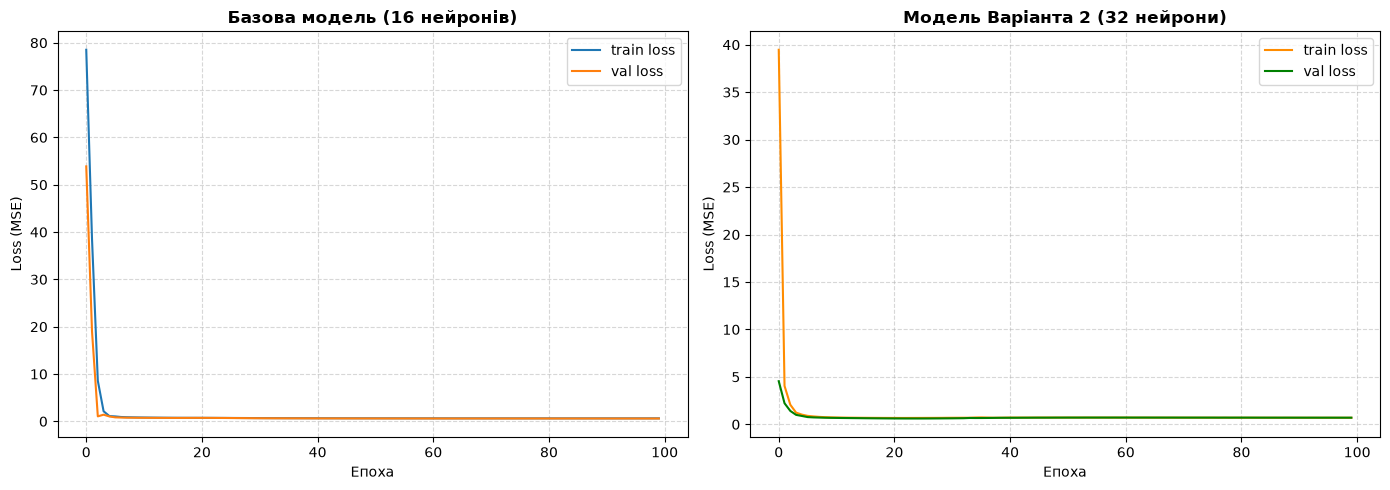

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_base.history["loss"], label="train loss")
plt.plot(history_base.history["val_loss"], label="val loss")
plt.title("Базова модель (16 нейронів)", fontweight="bold")
plt.xlabel("Епоха"); plt.ylabel("Loss (MSE)")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(history_v2.history["loss"], label="train loss", color="darkorange")
plt.plot(history_v2.history["val_loss"], label="val loss", color="green")
plt.title("Модель Варіанта 2 (32 нейрони)", fontweight="bold")
plt.xlabel("Епоха"); plt.ylabel("Loss (MSE)")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

best_val_loss_base = min(history_base.history["val_loss"])
best_val_loss_v2 = min(history_v2.history["val_loss"])

if best_val_loss_v2 < best_val_loss_base:
    best_model = model_v2
    best_name = "Модель Варіанта 2 (32 нейрони)"
else:
    best_model = base_model
    best_name = "Базова модель (16 нейронів)"

print(f"Найкраща за validation виявилася: {best_name}\n")

test_metrics_base = base_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
test_metrics_v2 = model_v2.evaluate(x_test, y_test, return_dict=True, verbose=0)

comparison_df = pd.DataFrame({
    "Найменший val_loss": [best_val_loss_base, best_val_loss_v2],
    "Test MSE": [test_metrics_base["loss"], test_metrics_v2["loss"]],
    "Test MAE": [test_metrics_base["mae"], test_metrics_v2["mae"]]
}, index=["Базова модель", "Модель Варіанта 2 (32 нейрони)"])

display(comparison_df.round(4))

x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
preds = best_model.predict(x_new, verbose=0)
print("\nПрогнози найкращої моделі для x_new = [-4, 0, 4]:")
for xv, yv in zip(x_new.flatten(), preds.flatten()):
    print(f"x = {xv:2.1f} -> прогноз y = {yv:2.4f}")

Найкраща за validation виявилася: Базова модель (16 нейронів)



,Найменший val_loss,Test MSE,Test MAE
Базова модель,0.5986,0.6071,0.6143
Модель Варіанта 2 (32 нейрони),0.6153,0.7465,0.6861



Прогнози найкращої моделі для x_new = [-4, 0, 4]:
x = -4.0 -> прогноз y = -10.3004
x = 0.0 -> прогноз y = 1.8522
x = 4.0 -> прогноз y = 14.0555


In [8]:
best_model.save("lab5_model.keras")
print("Модель успішно збережено у файл 'lab5_model.keras'")

restored_model = keras.models.load_model("lab5_model.keras")

np.testing.assert_allclose(
    best_model.predict(x_new, verbose=0),
    restored_model.predict(x_new, verbose=0),
    rtol=1e-5
)
print("Перевірка успішна: прогнози збереженої та завантаженої моделей повністю збігаються!")

Модель успішно збережено у файл 'lab5_model.keras'
Перевірка успішна: прогнози збереженої та завантаженої моделей повністю збігаються!


## Загальний висновок

У ході лабораторної роботи №5 успішно освоєно роботу з бібліотекою TensorFlow:
1. Виконано вправу з тензорами, досліджено їхні розмірності, типи даних та механізми broadcasting.
2. Згенеровано нелінійні дані регресії та виконано їхній поділ на тренувальну, валідаційну та тестову вибірки (70/15/15) із фіксованим `SEED = 42`.
3. Побудовано базову модель нейронної мережі Keras та модель за Варіантом 2 (збільшено кількість нейронів до 32 у прихованих шарах).
4. Проведено навчання, побудовано графіки функцій втрат, оцінено результати на тестовій вибірці та виконано прогнозування.
5. Збережено найкращу модель у форматі `.keras` та перевірено ідентичність завантажених прогнозів.